# test 결함 수를 늘린 평가 — 기존 입력 vs 정렬 입력 × 합성 비율

baseline test 결함이 19장뿐이라 지표가 천장(0.95+)에 붙고 결함 1장이 F2 를 약 0.05 움직인다. 이 노트북은 480장을 합쳐
**test 결함을 N장(30/40/50, 환경변수 `NTEST`)으로 늘린 새 분할**(`splits/synth_test{N}_split.csv`)에서 같은 실험을 다시 한다.

- 분할: 유형당 N/5 장씩 test 결함, 정상 test 는 baseline 비율 유지. N=30 ⊂ 40 ⊂ 50 (nested). 나머지는 train → 80/20 으로 train/val.
- 합성 풀: 이 분할의 train 안에서만 소스·대상을 뽑아 N 별로 새로 만든다(누수 없음). test/val 은 real only.
- 입력 2종: `base`(Resize256→224, 기존) / `align`(나사를 세워 128×384). 합성 비율 `0 / 0.25 / 0.5 / 1.0` × 시드 5개.
- 학습 설정은 기존과 동일(ResNet-18, Adam 1e-4, weight 2.0, 40 epoch, val F2 최고 epoch, patience 10).
- **이 분할의 수치는 baseline 분할(55장) 결과와 직접 비교하지 않는다.**

In [1]:
import os, sys, time, copy
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() or not (ROOT / "splits").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("레포 루트를 찾지 못함")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import fbeta_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from pytorch_grad_cam import GradCAM, LayerCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

from src.common.paths import SYNTH_EXP_DIR, OUTPUTS_DIR, SPLITS_DIR
from src.common.utils import set_seed
from src.supervised.dataset import train_transform, val_transform
from src.supervised.model import build_model_bin
from src.supervised.loc_eval import load_mask, inv_normalize, _compute_pixel_metrics
from src.supervised import synth, align, bigtest

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

W1109 14:48:47.629000 20132 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


device: cuda


## 1. 설정

In [2]:
NTEST = int(os.environ.get("NTEST", "40"))            # test 결함 수 (30 / 40 / 50)
QUICK = os.environ.get("SYNTH_QUICK") == "1"
MODES = ["base", "align"]
RATIOS = [0.0, 0.25, 0.5, 1.0]
SEEDS = [0, 1, 2, 3, 4]
EPOCHS, PATIENCE, BAD_WEIGHT, BATCH, LR = 40, 10, 2.0, 16, 1e-4
SPLIT_SEED, POOL_SEED, SCALE = 42, 7, 0.4
CAM_COMBOS = [("GradCAM", "layer4"), ("LayerCAM", "layer3")]
METHODS = {"GradCAM": GradCAM, "LayerCAM": LayerCAM}
if QUICK:
    RATIOS, SEEDS, EPOCHS = [0.0, 0.5], [0], 3
TAG = f"t{NTEST}" + ("_quick" if QUICK else "")
EXP_DIR = os.path.join(SYNTH_EXP_DIR, TAG); os.makedirs(EXP_DIR, exist_ok=True)
RUNS_CSV = os.path.join(EXP_DIR, "runs.csv")
POOL_DIR = os.path.join(OUTPUTS_DIR, f"synthetic_{TAG}")
POOL_CSV = os.path.join(SPLITS_DIR, f"synthetic_split_{TAG}.csv")
print(TAG, "| modes", MODES, "| ratios", RATIOS, "| seeds", SEEDS)

t30 | modes ['base', 'align'] | ratios [0.0, 0.25, 0.5, 1.0] | seeds [0, 1, 2, 3, 4]


## 2. 분할 · 합성 풀

In [3]:
def to_rec(r):
    return {"path": r["path"], "type": r["class"], "label": 0 if r["class"] == "good" else 1, "mask": r["mask"]}
tr_all, te_all = bigtest.make_split(NTEST, SPLIT_SEED)
real_train, test_recs = [to_rec(r) for r in tr_all], [to_rec(r) for r in te_all]
tr_idx, val_idx = train_test_split(np.arange(len(real_train)), test_size=0.2,
                                   stratify=[r["type"] for r in real_train], random_state=SPLIT_SEED)
tr_recs = [real_train[i] for i in tr_idx]; val_recs = [real_train[i] for i in val_idx]
P = lambda rs: {r["path"] for r in rs}
assert not (P(tr_recs) & P(val_recs)) and not (P(tr_recs) & P(test_recs)) and not (P(val_recs) & P(test_recs))

n_normal = sum(r["type"] == "good" for r in tr_recs)
ALLOC = {r: synth.allocate(n_normal, r) for r in RATIOS}
PER_TYPE = max(max(a.values()) for a in ALLOC.values())
pool = synth.load_pool(POOL_CSV)
if pool is None or min(len(v) for v in pool.values()) < PER_TYPE:
    t0 = time.time()
    pool = synth.build_pool({t: [r for r in tr_recs if r["type"] == t] for t in synth.TYPES},
                            [r for r in tr_recs if r["type"] == "good"], PER_TYPE, synth.SynthConfig(), POOL_SEED, POOL_DIR, POOL_CSV)
    print(f"합성 풀 생성 {sum(len(v) for v in pool.values())}장, {time.time()-t0:.0f}s")
assert {r["source"] for v in pool.values() for r in v} <= P(tr_recs), "합성 소스가 train 밖"

def train_set(ratio):
    s = synth.take(pool, ALLOC[ratio]) if ratio > 0 else []
    assert not (P(s) & (P(val_recs) | P(test_recs)))
    return tr_recs + s, len(s)

defects = [r for r in test_recs if r["label"] == 1]
GT = np.stack([load_mask(r["mask"]) for r in defects])
pd.DataFrame([{"split": n, "정상": sum(r["type"] == "good" for r in rs), "결함": sum(r["label"] for r in rs)}
              for n, rs in [("train", tr_recs), ("val", val_recs), ("test", test_recs)]])

,split,정상,결함
0,train,243,71
1,val,61,18
2,test,57,30


## 3. 입력 · 학습 · 평가

In [4]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
assert isinstance(train_transform.transforms[0], transforms.Resize)
TF = {"base": (transforms.Compose(train_transform.transforms[1:]), transforms.Compose(val_transform.transforms[1:])),
      "align": (transforms.Compose([transforms.RandomAffine(8, translate=(0.04, 0.03), scale=(0.9, 1.1), fill=200),
                                    transforms.RandomHorizontalFlip(0.5), transforms.ColorJitter(brightness=0.3, contrast=0.3),
                                    transforms.ToTensor(), transforms.Normalize(MEAN, STD)]),
                transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)]))}
_resize = train_transform.transforms[0]
_CACHE = {}
def load_img(mode, path):
    k = (mode, path)
    if k not in _CACHE:
        _CACHE[k] = _resize(Image.open(path).convert("RGB")) if mode == "base" else Image.fromarray(align.align_scaled(path, SCALE))
    return _CACHE[k]

class DS(Dataset):
    def __init__(self, recs, mode, train): self.recs, self.mode, self.tf = recs, mode, TF[mode][0 if train else 1]
    def __len__(self): return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]; return self.tf(load_img(self.mode, r["path"])), r["label"]

def loader(recs, mode, train):
    return DataLoader(DS(recs, mode, train), batch_size=BATCH, shuffle=train, num_workers=0)

def train_one(mode, ratio, seed):
    set_seed(seed)
    recs, n_syn = train_set(ratio)
    tl, vl = loader(recs, mode, True), loader(val_recs, mode, False)
    model = build_model_bin("resnet18").to(device)
    crit = nn.CrossEntropyLoss(weight=torch.tensor([1.0, BAD_WEIGHT]).to(device))
    opt = optim.Adam(model.parameters(), lr=LR)
    best_f2, best_ep, best_state, bad = 0.0, 0, copy.deepcopy(model.state_dict()), 0
    for ep in range(EPOCHS):
        model.train()
        for x, y in tl:
            opt.zero_grad(); crit(model(x.to(device)), y.to(device)).backward(); opt.step()
        model.eval(); yt, yp = [], []
        with torch.no_grad():
            for x, y in vl:
                yp.extend(model(x.to(device)).argmax(1).cpu().numpy()); yt.extend(y.numpy())
        f2 = fbeta_score(yt, yp, beta=2, pos_label=1, zero_division=0)
        if f2 > best_f2: best_f2, best_ep, best_state, bad = f2, ep + 1, copy.deepcopy(model.state_dict()), 0
        else: bad += 1
        if bad >= PATIENCE: break
    model.load_state_dict(best_state); model.eval()
    return model, best_f2, best_ep, len(recs), n_syn

def cam_maps(model, mode, method, layer, recs):
    x = torch.stack([TF[mode][1](load_img(mode, r["path"])) for r in recs]).to(device)
    with METHODS[method](model=model, target_layers=[getattr(model, layer)[-1]]) as cam:
        cams = cam(input_tensor=x, targets=[ClassifierOutputTarget(1)] * len(x))
    if mode == "base":
        return list(cams)
    return [align.cam_to_eval_frame(c, r["path"]) for c, r in zip(cams, recs)]

def evaluate(model, mode):
    yt, yp, pr = [], [], []
    with torch.no_grad():
        for x, y in loader(test_recs, mode, False):
            lg = model(x.to(device))
            yp.extend(lg.argmax(1).cpu().numpy()); pr.extend(torch.softmax(lg, 1)[:, 1].cpu().numpy()); yt.extend(y.numpy())
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    out = dict(precision=precision_score(yt, yp, zero_division=0), recall=recall_score(yt, yp),
               f2=fbeta_score(yt, yp, beta=2, pos_label=1, zero_division=0), img_auroc=roc_auc_score(yt, pr),
               tn=tn, fp=fp, fn=fn, tp=tp)
    for m, l in CAM_COMBOS:
        res = _compute_pixel_metrics(cam_maps(model, mode, m, l, defects), list(GT))
        out[f"pa_{m}_{l}"], out[f"aupro_{m}_{l}"] = res["pixel_auroc"], res["aupro"]
    return out
print("정의 완료")

정의 완료


## 4. 실행 — (입력 × 비율 × 시드), `runs.csv` 에 누적 저장(이어서 실행 가능)

In [5]:
rows = pd.read_csv(RUNS_CSV).to_dict("records") if os.path.exists(RUNS_CSV) else []
done = {(r["mode"], float(r["ratio"]), int(r["seed"])) for r in rows}
total = len(MODES) * len(RATIOS) * len(SEEDS)
for seed in SEEDS:
    for mode in MODES:
        for ratio in RATIOS:
            if (mode, float(ratio), seed) in done: continue
            t0 = time.time()
            model, vf2, bep, ntr, nsyn = train_one(mode, ratio, seed)
            res = evaluate(model, mode)
            rows.append(dict(mode=mode, ratio=ratio, seed=seed, n_train=ntr, n_synth=nsyn, best_epoch=bep, val_f2=vf2,
                             seconds=round(time.time() - t0), **res))
            pd.DataFrame(rows).to_csv(RUNS_CSV, index=False)
            print(f"[{len(rows):2d}/{total}] {mode:5s} ratio={ratio:<4} seed={seed} | val {vf2:.3f} (ep {bep}) | test F2 {res['f2']:.3f} "
                  f"R {res['recall']:.3f} P {res['precision']:.3f} AUROC {res['img_auroc']:.3f} | AUPRO {res['aupro_GradCAM_layer4']:.3f} | {time.time()-t0:.0f}s", flush=True)
            del model; torch.cuda.empty_cache()
pd.DataFrame(rows).to_csv(RUNS_CSV, index=False)
print("완료:", len(rows), "runs")

완료: 40 runs


## 5. 결과 — 입력별로 합성 비율의 효과 (시드 평균 ± 표준편차)

`Δ` 는 합성 없음(0.0) 대비 평균 차이, `(p, 이긴 시드 수)` 는 시드로 짝지은 t-test.

In [6]:
res = pd.read_csv(RUNS_CSV)
seeds, ratios = sorted(res.seed.unique()), sorted(res.ratio.unique())
KEYS = [("f2", "Test F2"), ("recall", "Recall"), ("precision", "Precision"), ("fp", "정상 오경보 FP"), ("fn", "놓친 결함 FN"),
        ("img_auroc", "Image AUROC"), ("pa_GradCAM_layer4", "Pixel AUROC GradCAM/L4"), ("aupro_GradCAM_layer4", "AUPRO GradCAM/L4"),
        ("pa_LayerCAM_layer3", "Pixel AUROC LayerCAM/L3"), ("aupro_LayerCAM_layer3", "AUPRO LayerCAM/L3"), ("val_f2", "Best val F2"), ("best_epoch", "선택 epoch")]
S = lambda mode, key, r: res[(res["mode"] == mode) & (res.ratio == r)].set_index("seed")[key].sort_index()

def by_ratio(mode):
    out = []
    for key, label in KEYS:
        row, ref = {"지표": label}, S(mode, key, ratios[0])
        for r in ratios:
            s = S(mode, key, r); row[f"{r}"] = f"{s.mean():.3f} ± {s.std(ddof=1):.3f}"
            if r != ratios[0]:
                d = s - ref; row[f"Δ({r})"] = f"{d.mean():+.3f} (p={stats.ttest_rel(s, ref).pvalue:.2f}, {(d > 0).sum()}/{len(d)})"
        out.append(row)
    return pd.DataFrame(out).set_index("지표")
for m in ["base", "align"]:
    print(f"=== {m} 입력 (test 결함 {NTEST}장) ==="); display(by_ratio(m))

=== base 입력 (test 결함 30장) ===


,0.0,0.25,Δ(0.25),0.5,Δ(0.5),1.0,Δ(1.0)
지표,,,,,,,
Test F2,0.708 ± 0.074,0.722 ± 0.103,"+0.015 (p=0.85, 3/5)",0.792 ± 0.101,"+0.084 (p=0.04, 5/5)",0.777 ± 0.114,"+0.069 (p=0.43, 3/5)"
Recall,0.700 ± 0.097,0.707 ± 0.132,"+0.007 (p=0.95, 3/5)",0.833 ± 0.113,"+0.133 (p=0.02, 4/5)",0.813 ± 0.150,"+0.113 (p=0.34, 3/5)"
Precision,0.775 ± 0.132,0.831 ± 0.087,"+0.057 (p=0.53, 3/5)",0.675 ± 0.111,"-0.100 (p=0.28, 2/5)",0.681 ± 0.091,"-0.094 (p=0.31, 1/5)"
정상 오경보 FP,7.000 ± 5.339,4.800 ± 3.114,"-2.200 (p=0.53, 2/5)",12.800 ± 6.979,"+5.800 (p=0.26, 4/5)",12.000 ± 5.292,"+5.000 (p=0.29, 4/5)"
놓친 결함 FN,9.000 ± 2.915,8.800 ± 3.962,"-0.200 (p=0.95, 2/5)",5.000 ± 3.391,"-4.000 (p=0.02, 0/5)",5.600 ± 4.506,"-3.400 (p=0.34, 2/5)"
Image AUROC,0.886 ± 0.026,0.917 ± 0.033,"+0.031 (p=0.29, 4/5)",0.889 ± 0.094,"+0.004 (p=0.94, 3/5)",0.901 ± 0.077,"+0.016 (p=0.69, 3/5)"
Pixel AUROC GradCAM/L4,0.756 ± 0.092,0.848 ± 0.035,"+0.092 (p=0.17, 4/5)",0.857 ± 0.066,"+0.101 (p=0.05, 5/5)",0.888 ± 0.062,"+0.131 (p=0.10, 3/5)"
AUPRO GradCAM/L4,0.422 ± 0.166,0.600 ± 0.072,"+0.178 (p=0.16, 4/5)",0.623 ± 0.163,"+0.201 (p=0.05, 4/5)",0.713 ± 0.122,"+0.291 (p=0.06, 4/5)"
Pixel AUROC LayerCAM/L3,0.904 ± 0.050,0.954 ± 0.012,"+0.050 (p=0.09, 4/5)",0.954 ± 0.024,"+0.050 (p=0.03, 4/5)",0.969 ± 0.013,"+0.065 (p=0.08, 4/5)"


=== align 입력 (test 결함 30장) ===


,0.0,0.25,Δ(0.25),0.5,Δ(0.5),1.0,Δ(1.0)
지표,,,,,,,
Test F2,0.954 ± 0.038,0.934 ± 0.065,"-0.020 (p=0.65, 3/5)",0.964 ± 0.026,"+0.010 (p=0.49, 2/5)",0.972 ± 0.019,"+0.018 (p=0.51, 3/5)"
Recall,0.947 ± 0.051,0.927 ± 0.083,"-0.020 (p=0.71, 2/5)",0.960 ± 0.037,"+0.013 (p=0.48, 2/5)",0.973 ± 0.028,"+0.027 (p=0.48, 3/5)"
Precision,0.988 ± 0.028,0.975 ± 0.040,"-0.013 (p=0.64, 1/5)",0.981 ± 0.028,"-0.007 (p=0.37, 0/5)",0.968 ± 0.022,"-0.020 (p=0.28, 1/5)"
정상 오경보 FP,0.400 ± 0.894,0.800 ± 1.304,"+0.400 (p=0.65, 2/5)",0.600 ± 0.894,"+0.200 (p=0.37, 1/5)",1.000 ± 0.707,"+0.600 (p=0.30, 3/5)"
놓친 결함 FN,1.600 ± 1.517,2.200 ± 2.490,"+0.600 (p=0.71, 2/5)",1.200 ± 1.095,"-0.400 (p=0.48, 1/5)",0.800 ± 0.837,"-0.800 (p=0.48, 2/5)"
Image AUROC,0.998 ± 0.003,0.998 ± 0.004,"-0.000 (p=0.81, 2/5)",0.997 ± 0.004,"-0.001 (p=0.73, 2/5)",0.999 ± 0.001,"+0.001 (p=0.52, 2/5)"
Pixel AUROC GradCAM/L4,0.971 ± 0.012,0.979 ± 0.010,"+0.007 (p=0.36, 3/5)",0.982 ± 0.008,"+0.010 (p=0.29, 3/5)",0.984 ± 0.011,"+0.013 (p=0.25, 4/5)"
AUPRO GradCAM/L4,0.888 ± 0.035,0.918 ± 0.041,"+0.029 (p=0.26, 4/5)",0.937 ± 0.021,"+0.049 (p=0.09, 4/5)",0.935 ± 0.045,"+0.047 (p=0.25, 4/5)"
Pixel AUROC LayerCAM/L3,0.985 ± 0.007,0.990 ± 0.003,"+0.005 (p=0.13, 3/5)",0.992 ± 0.001,"+0.007 (p=0.07, 5/5)",0.992 ± 0.001,"+0.008 (p=0.09, 5/5)"


## 6. 같은 비율에서 기존 입력 vs 정렬 입력

--- Test F2


,기존,정렬,Δ(정렬−기존)
합성 비율,,,
0.00,0.708 ± 0.074,0.954 ± 0.038,"+0.246 (p=0.00, 5/5)"
0.25,0.722 ± 0.103,0.934 ± 0.065,"+0.212 (p=0.01, 5/5)"
0.50,0.792 ± 0.101,0.964 ± 0.026,"+0.171 (p=0.03, 5/5)"
1.00,0.777 ± 0.114,0.972 ± 0.019,"+0.195 (p=0.02, 5/5)"


--- 정상 오경보 FP


,기존,정렬,Δ(정렬−기존)
합성 비율,,,
0.00,7.000 ± 5.339,0.400 ± 0.894,"-6.600 (p=0.03, 0/5)"
0.25,4.800 ± 3.114,0.800 ± 1.304,"-4.000 (p=0.02, 0/5)"
0.50,12.800 ± 6.979,0.600 ± 0.894,"-12.200 (p=0.02, 0/5)"
1.00,12.000 ± 5.292,1.000 ± 0.707,"-11.000 (p=0.01, 0/5)"


--- 놓친 결함 FN


,기존,정렬,Δ(정렬−기존)
합성 비율,,,
0.00,9.000 ± 2.915,1.600 ± 1.517,"-7.400 (p=0.01, 0/5)"
0.25,8.800 ± 3.962,2.200 ± 2.490,"-6.600 (p=0.02, 0/5)"
0.50,5.000 ± 3.391,1.200 ± 1.095,"-3.800 (p=0.10, 1/5)"
1.00,5.600 ± 4.506,0.800 ± 0.837,"-4.800 (p=0.06, 0/5)"


... (6 outputs left out)

C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\4201743163.py:17: UserWarning: Glyph 54633 (\N{HANGUL SYLLABLE HAB}) missing from font(s) DejaVu Sans.
  axs[0, 0].legend(); fig.suptitle(f"test 결함 {NTEST}장"); plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\4201743163.py:17: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  axs[0, 0].legend(); fig.suptitle(f"test 결함 {NTEST}장"); plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\4201743163.py:17: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  axs[0, 0].legend(); fig.suptitle(f"test 결함 {NTEST}장"); plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\4201743163.py:17: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  axs[0, 0].legend(); fig.suptitle(f"test 결함 {NTEST}장"); plt.tight_layout(); plt.show()


C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\4201743163.py:17: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  axs[0, 0].legend(); fig.suptitle(f"test 결함 {NTEST}장"); plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\4201743163.py:17: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  axs[0, 0].legend(); fig.suptitle(f"test 결함 {NTEST}장"); plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\4201743163.py:17: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  axs[0, 0].legend(); fig.suptitle(f"test 결함 {NTEST}장"); plt.tight_layout(); plt.show()


C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54633 (\N{HANGUL SYLLABLE HAB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


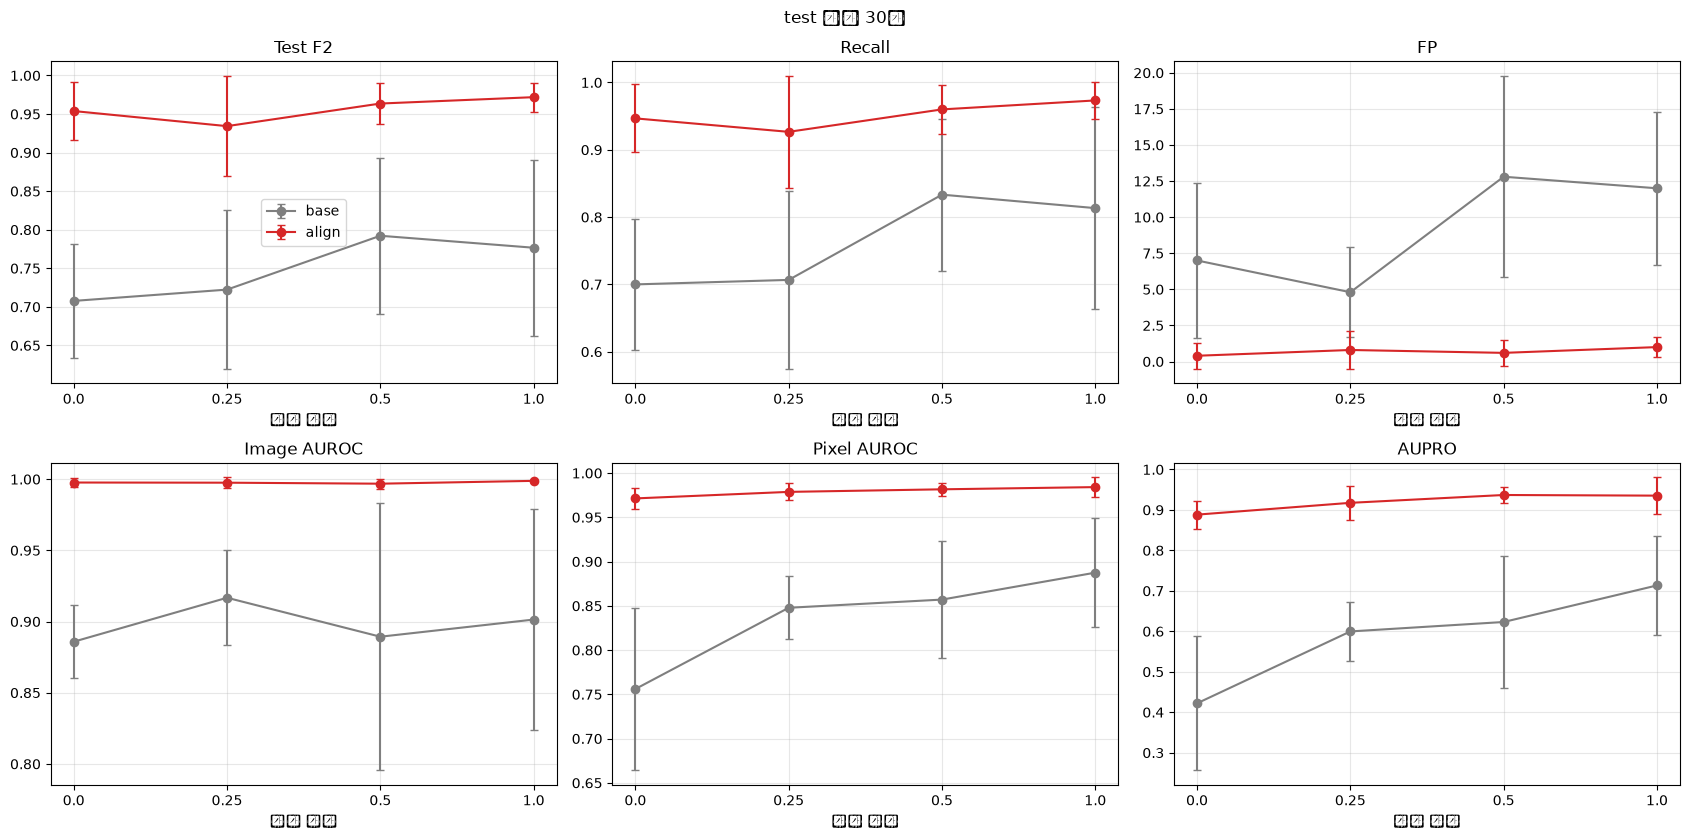

In [7]:
for key, label in [("f2", "Test F2"), ("fp", "정상 오경보 FP"), ("fn", "놓친 결함 FN"), ("img_auroc", "Image AUROC"),
                   ("pa_GradCAM_layer4", "Pixel AUROC (GradCAM/L4)"), ("aupro_GradCAM_layer4", "AUPRO (GradCAM/L4)")]:
    out = []
    for r in ratios:
        b, a = S("base", key, r), S("align", key, r); d = a - b
        out.append({"합성 비율": r, "기존": f"{b.mean():.3f} ± {b.std(ddof=1):.3f}", "정렬": f"{a.mean():.3f} ± {a.std(ddof=1):.3f}",
                    "Δ(정렬−기존)": f"{d.mean():+.3f} (p={stats.ttest_rel(a, b).pvalue:.2f}, {(d > 0).sum()}/{len(d)})"})
    print("---", label); display(pd.DataFrame(out).set_index("합성 비율"))

fig, axs = plt.subplots(2, 3, figsize=(17, 8.5))
for a, (key, label) in zip(axs.ravel(), [("f2", "Test F2"), ("recall", "Recall"), ("fp", "FP"), ("img_auroc", "Image AUROC"),
                                           ("pa_GradCAM_layer4", "Pixel AUROC"), ("aupro_GradCAM_layer4", "AUPRO")]):
    for mode, c in [("base", "tab:gray"), ("align", "tab:red")]:
        a.errorbar(range(len(ratios)), [S(mode, key, r).mean() for r in ratios], yerr=[S(mode, key, r).std(ddof=1) for r in ratios],
                   marker="o", capsize=3, label=mode, color=c)
    a.set_xticks(range(len(ratios))); a.set_xticklabels([str(r) for r in ratios]); a.set_xlabel("합성 비율"); a.set_title(label); a.grid(alpha=.3)
axs[0, 0].legend(); fig.suptitle(f"test 결함 {NTEST}장"); plt.tight_layout(); plt.show()

## 7. Grad-CAM — 같은 test 이미지, 합성 비율별 (입력 2종)

시드 0 모델로 비교한다. 행: test 결함 유형별 첫 장(고정 규칙) + 정상 1장, 열: 원본 / GT / 합성 비율별 CAM(제목의 `p` = bad 확률). 맵은 모두 224 평가 프레임에 그린다.
`runs.csv` 에는 모델을 저장하지 않았으므로, 저장본(`models/`)이 없으면 시드 0 으로 다시 학습해 저장한다(GPU 비결정성 때문에 표의 시드 0 수치와 약간 다를 수 있다 — 아래 출력에서 F2 를 비교).

재학습 base r=0.0: F2 0.671 (표의 시드 0: 0.671)


재학습 base r=0.25: F2 0.871 (표의 시드 0: 0.871)


재학습 base r=0.5: F2 0.849 (표의 시드 0: 0.849)


재학습 base r=1.0: F2 0.870 (표의 시드 0: 0.870)


C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 54633 (\N{HANGUL SYLLABLE HAB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()


C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 51077 (\N{HANGUL SYLLABLE IB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 47141 (\N{HANGUL SYLLABLE RYEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_2013

C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54633 (\N{HANGUL SYLLABLE HAB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51077 (\N{HANGUL SYLLABLE IB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47141 (\N{HANGUL SYLLABLE RYEOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  f

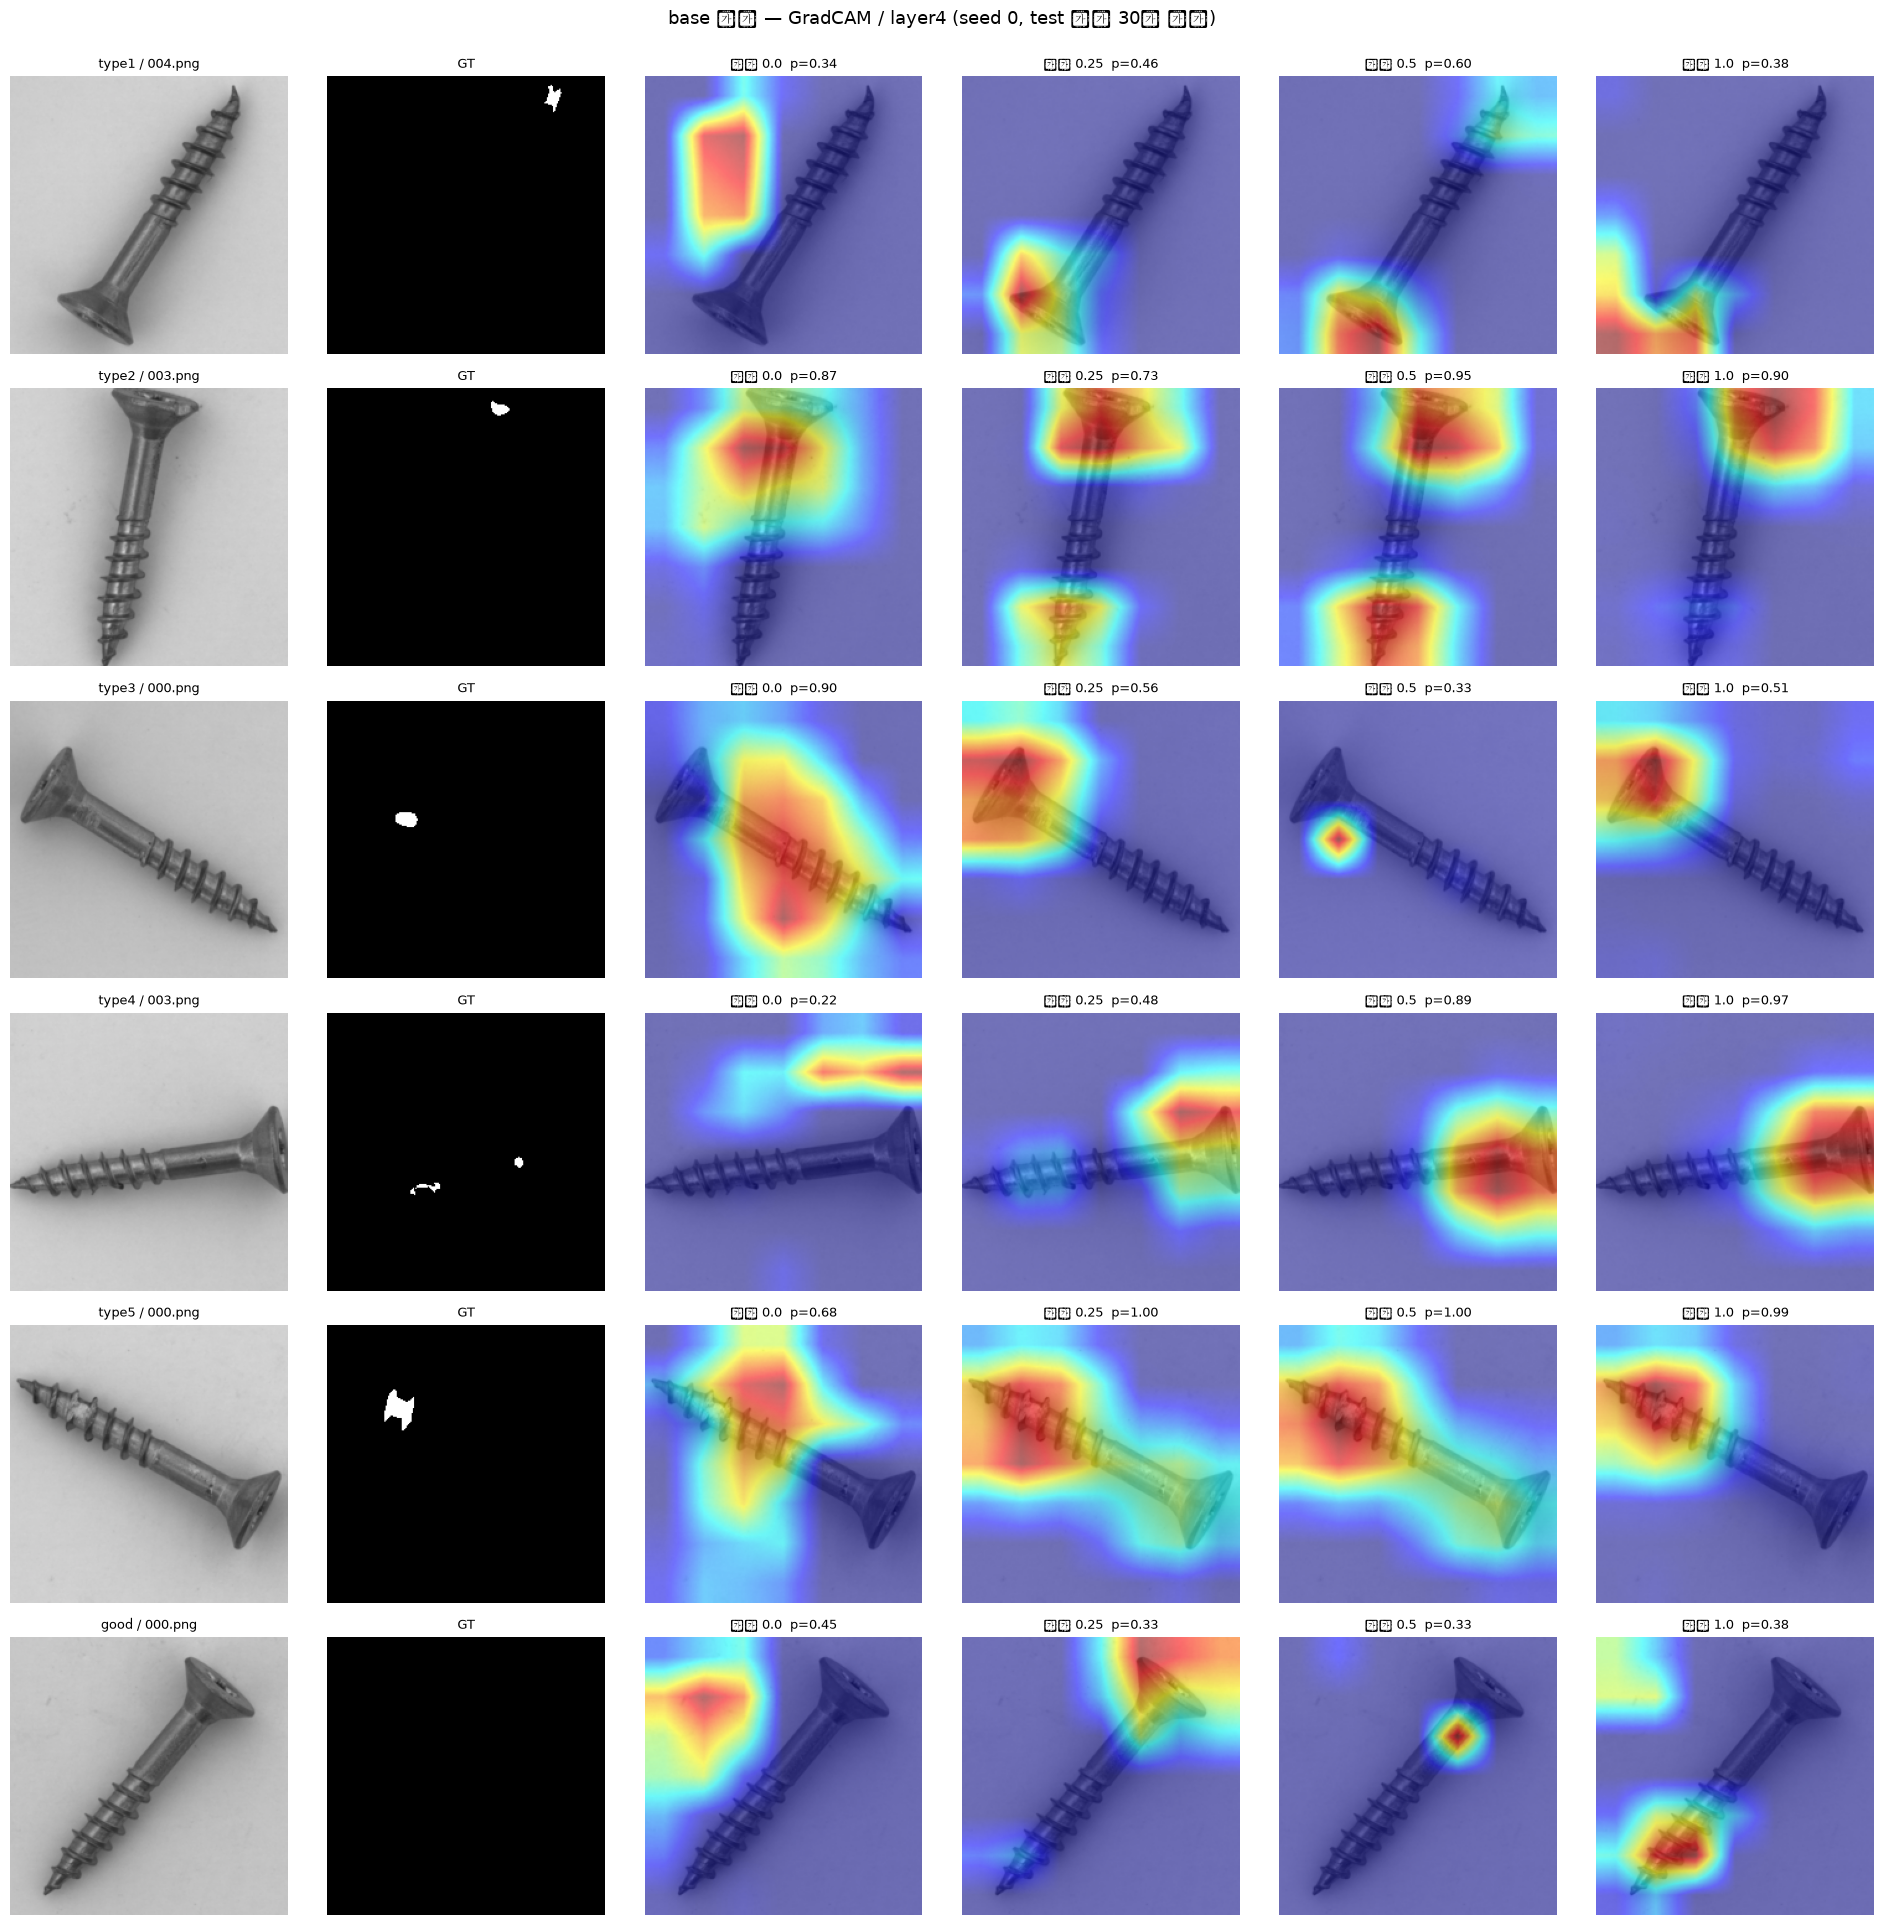

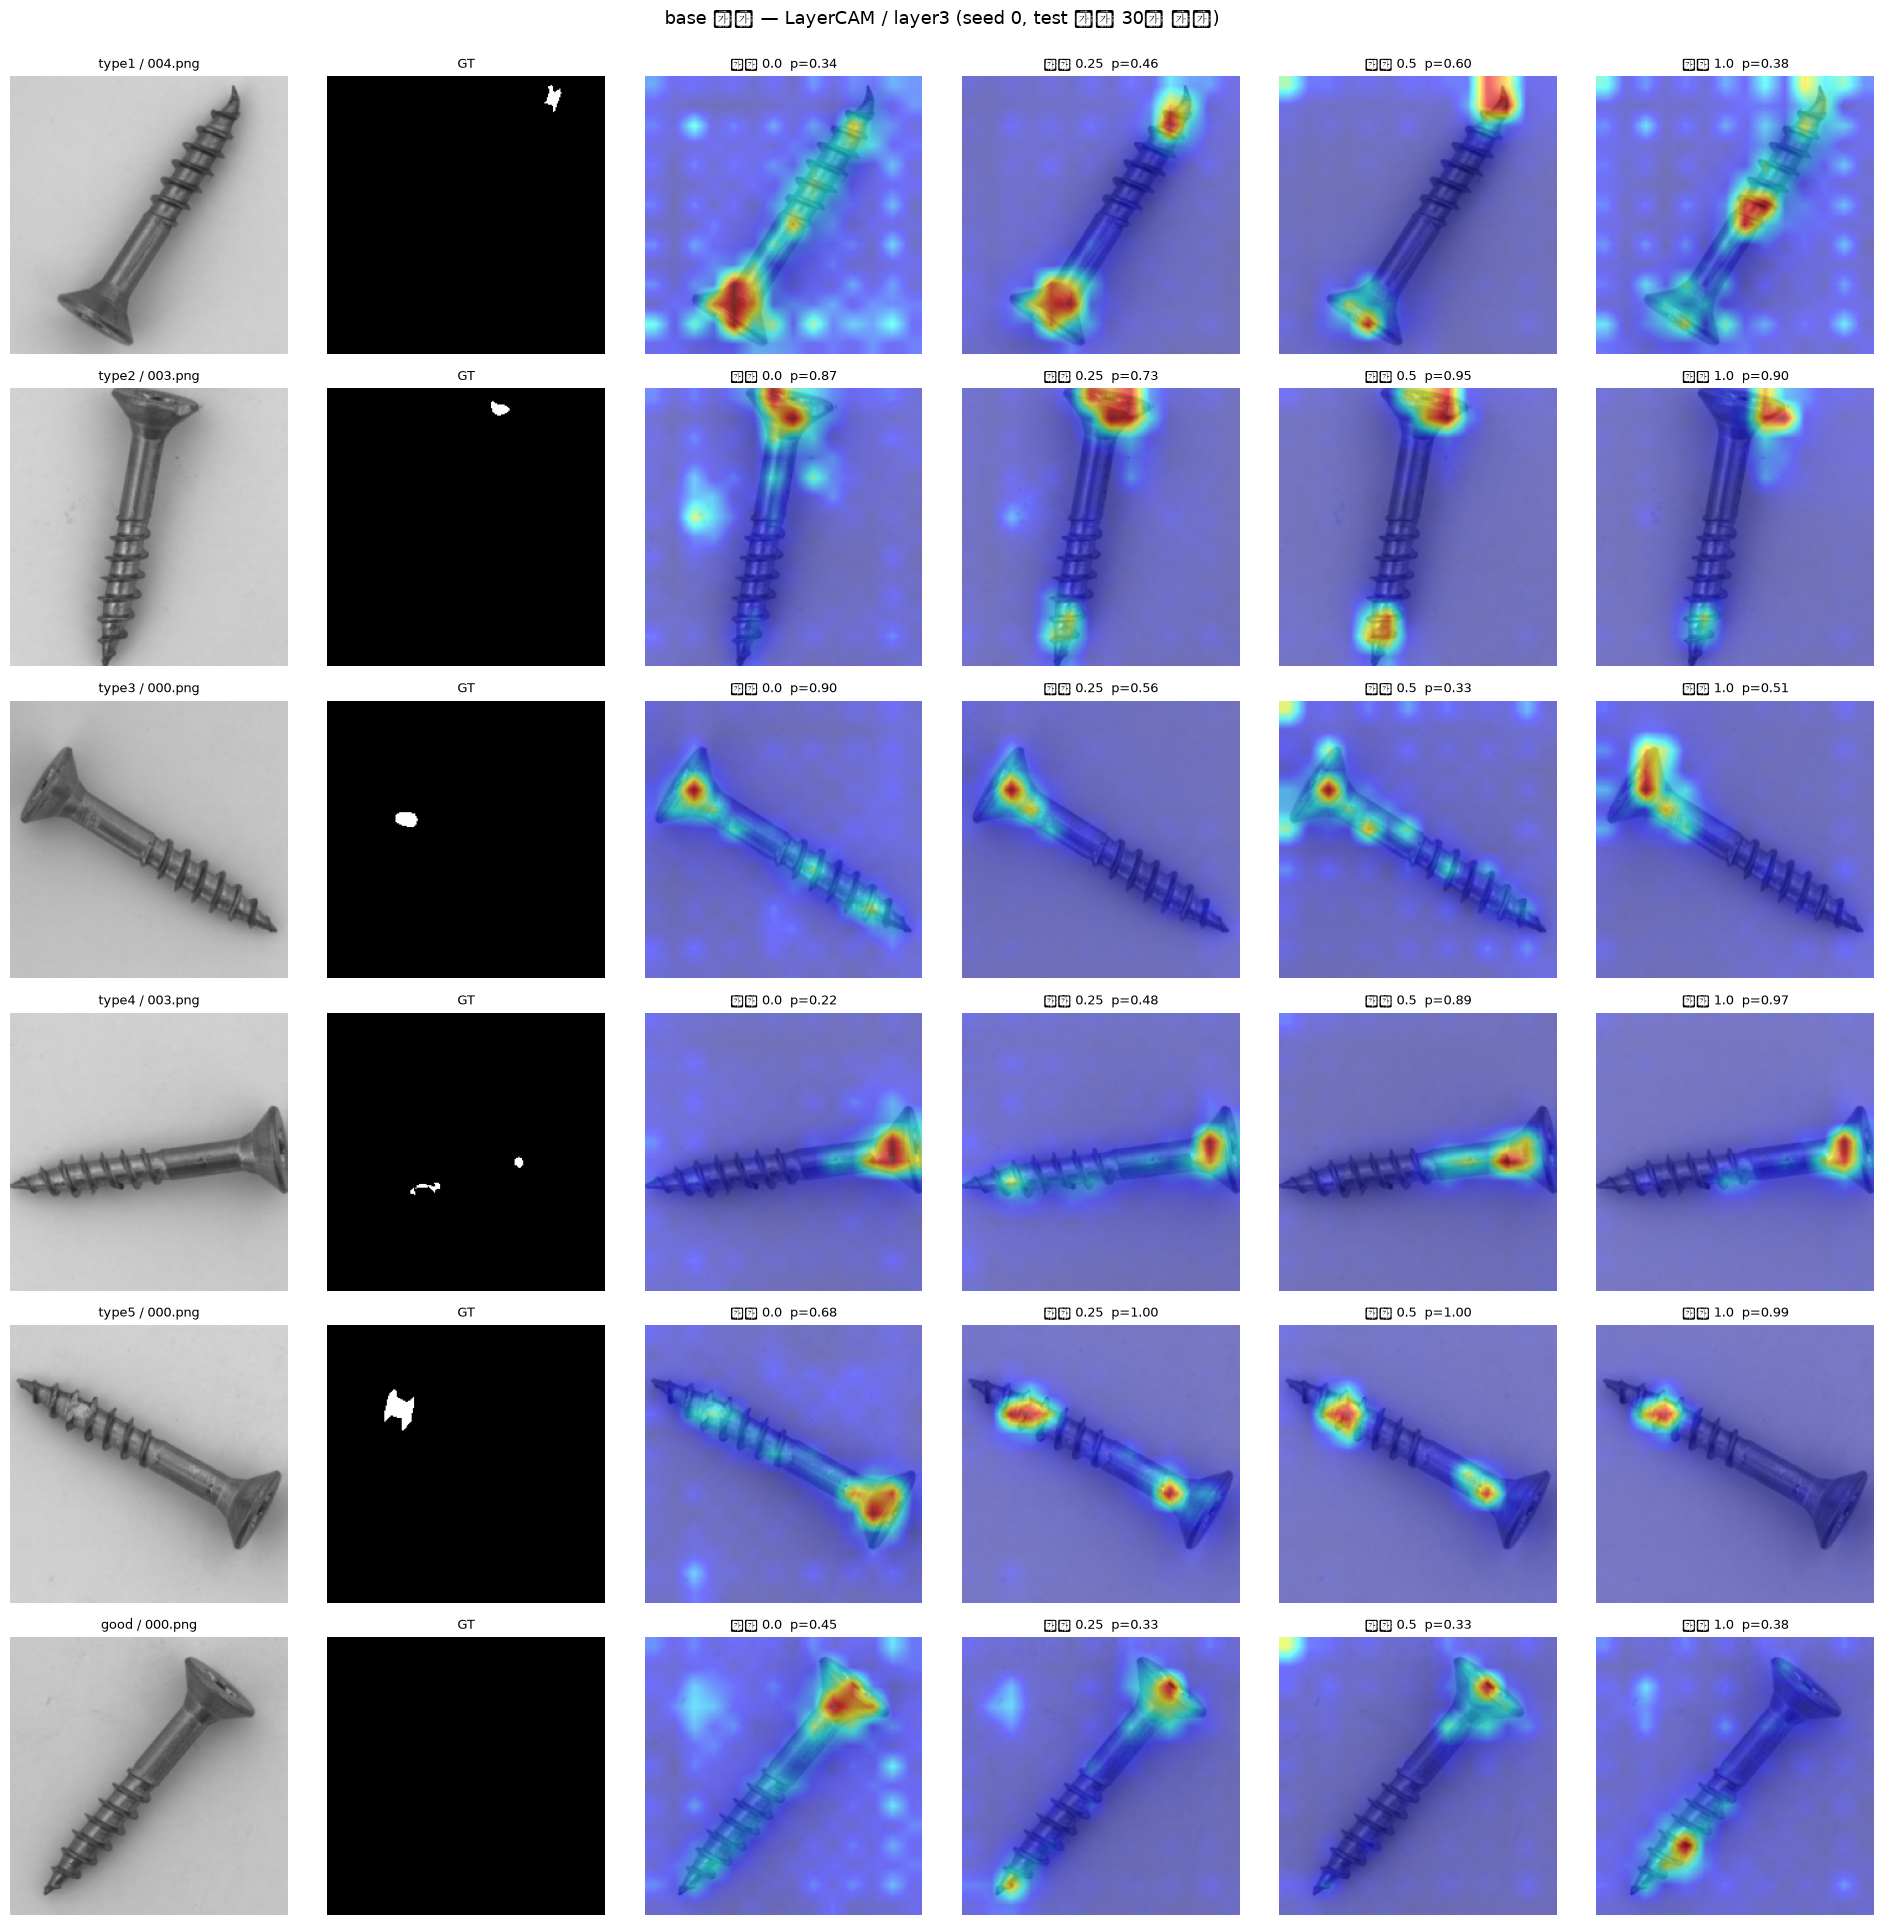

재학습 align r=0.0: F2 0.918 (표의 시드 0: 0.918)


재학습 align r=0.25: F2 0.980 (표의 시드 0: 0.980)


재학습 align r=0.5: F2 0.918 (표의 시드 0: 0.918)


재학습 align r=1.0: F2 0.987 (표의 시드 0: 0.987)


C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 54633 (\N{HANGUL SYLLABLE HAB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()


C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 51077 (\N{HANGUL SYLLABLE IB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 47141 (\N{HANGUL SYLLABLE RYEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_20132\3476210004.py:35: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_2013

C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54633 (\N{HANGUL SYLLABLE HAB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51077 (\N{HANGUL SYLLABLE IB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47141 (\N{HANGUL SYLLABLE RYEOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\screw_defect\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  f

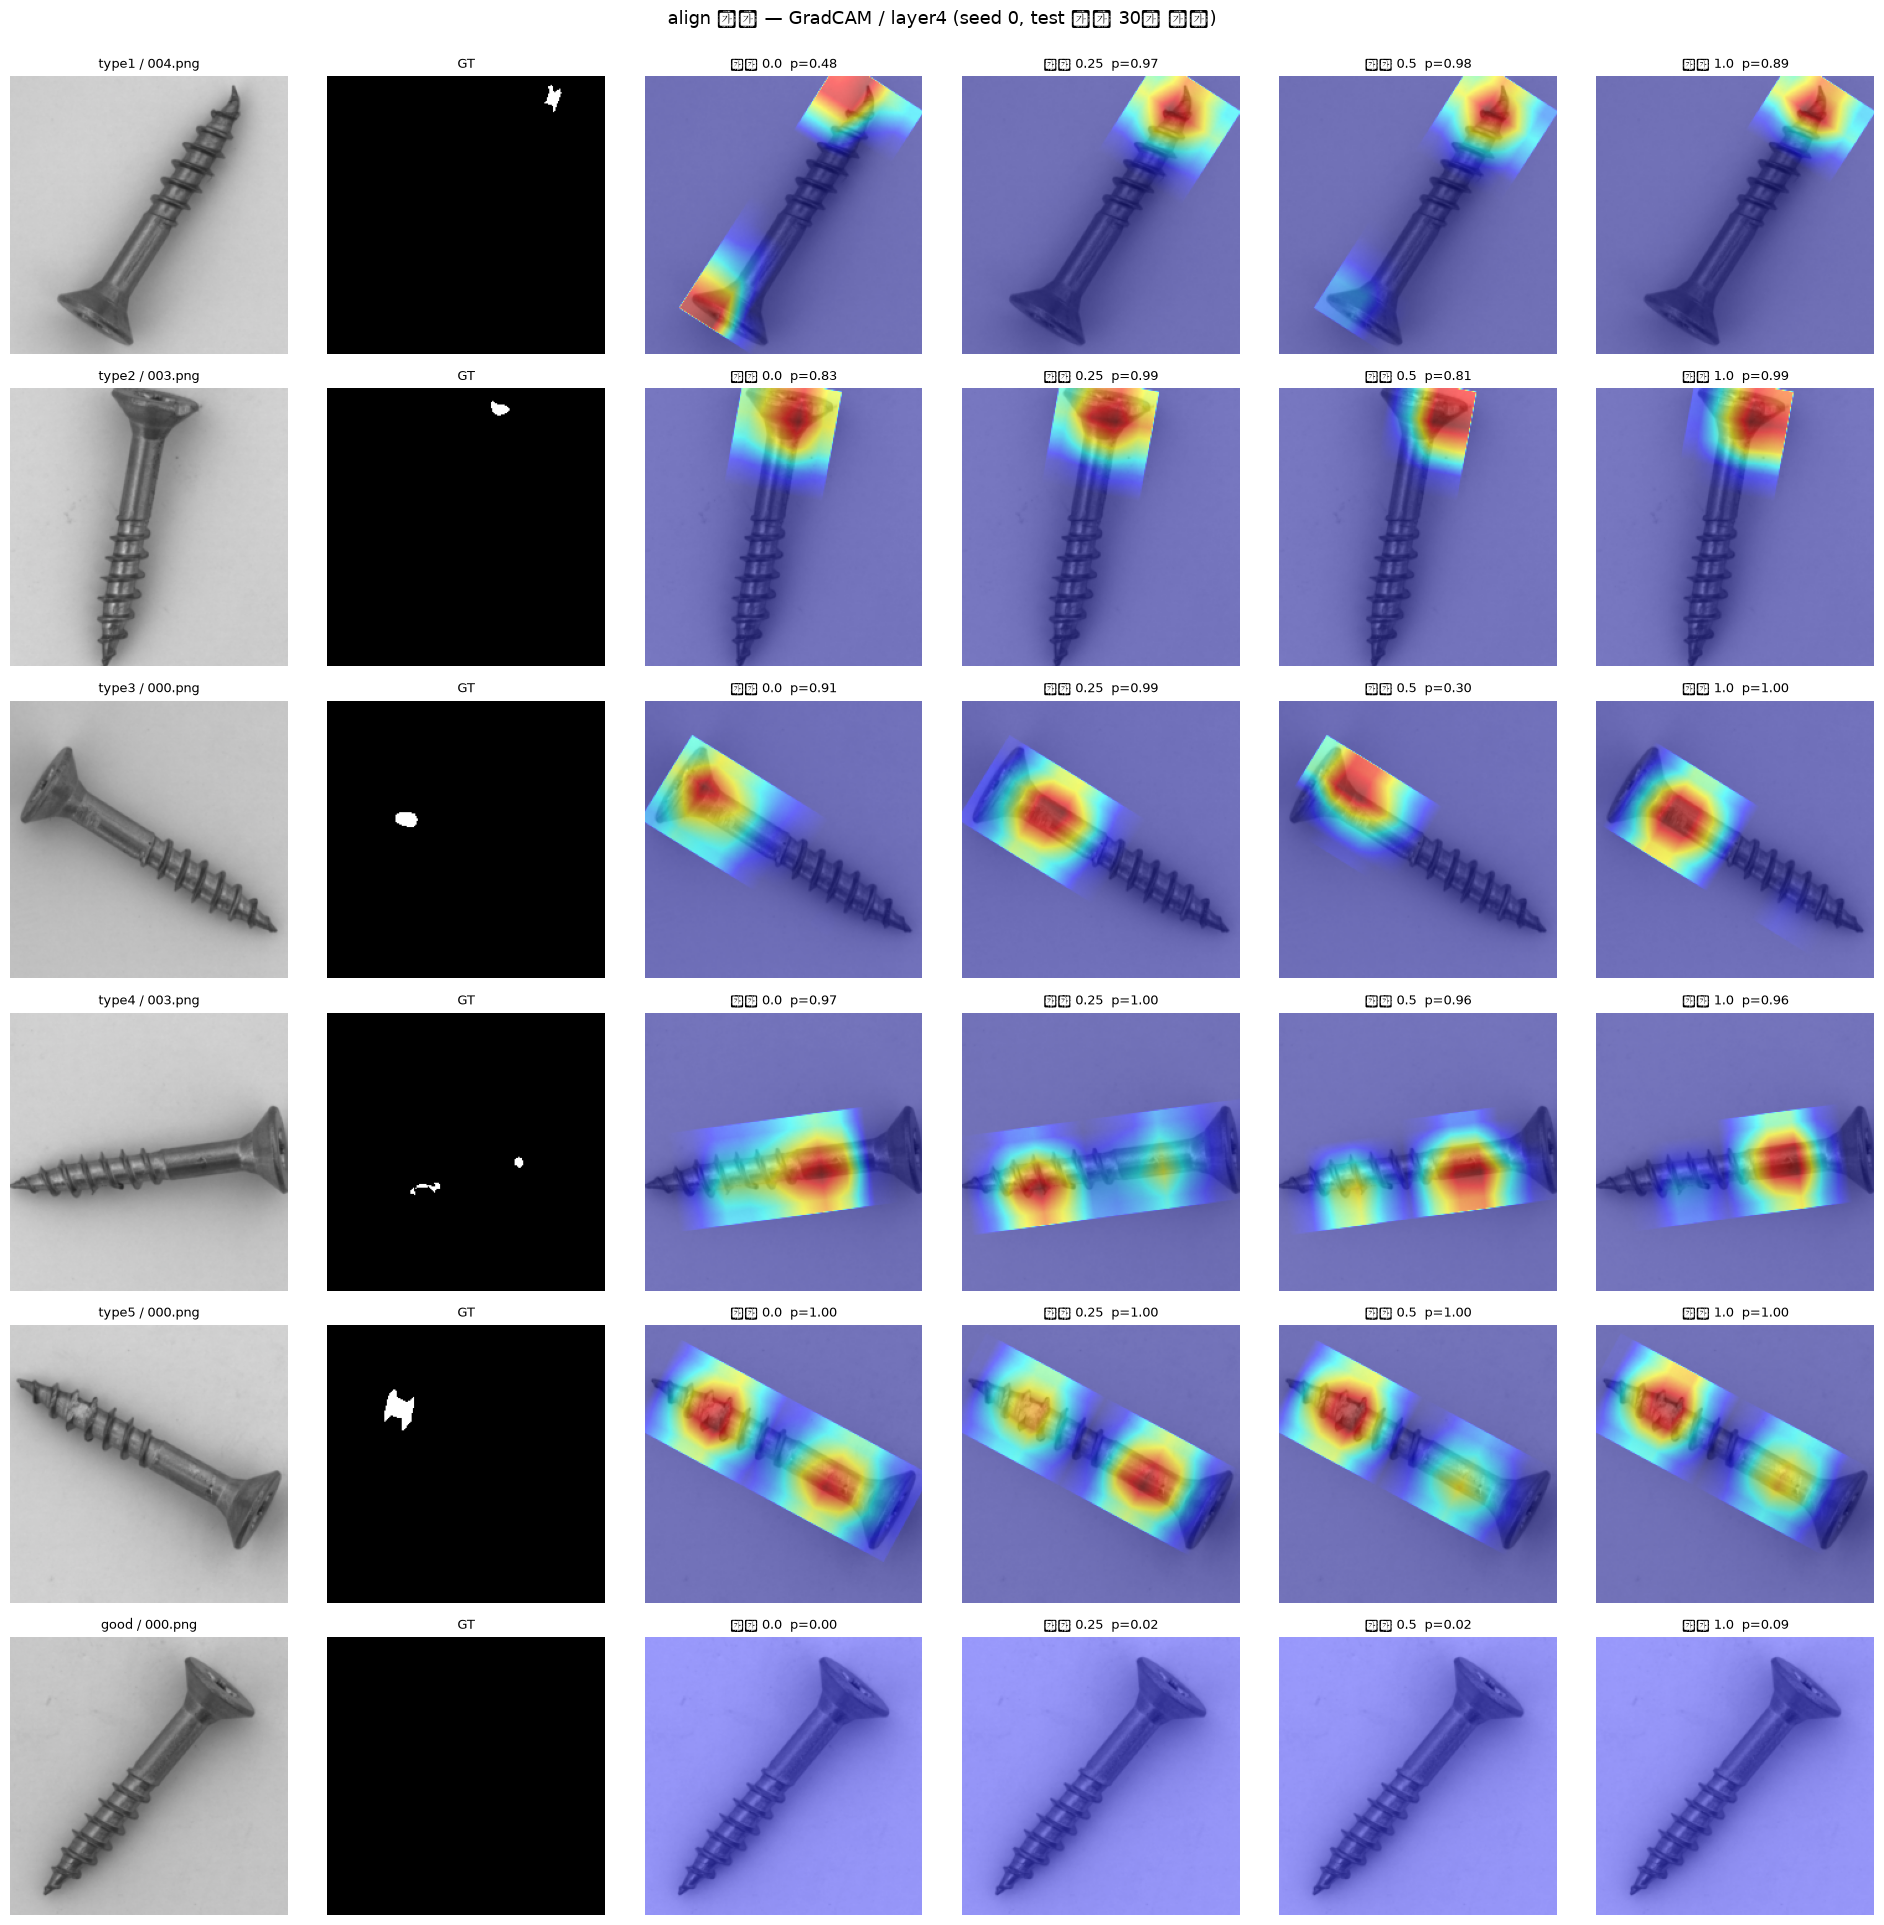

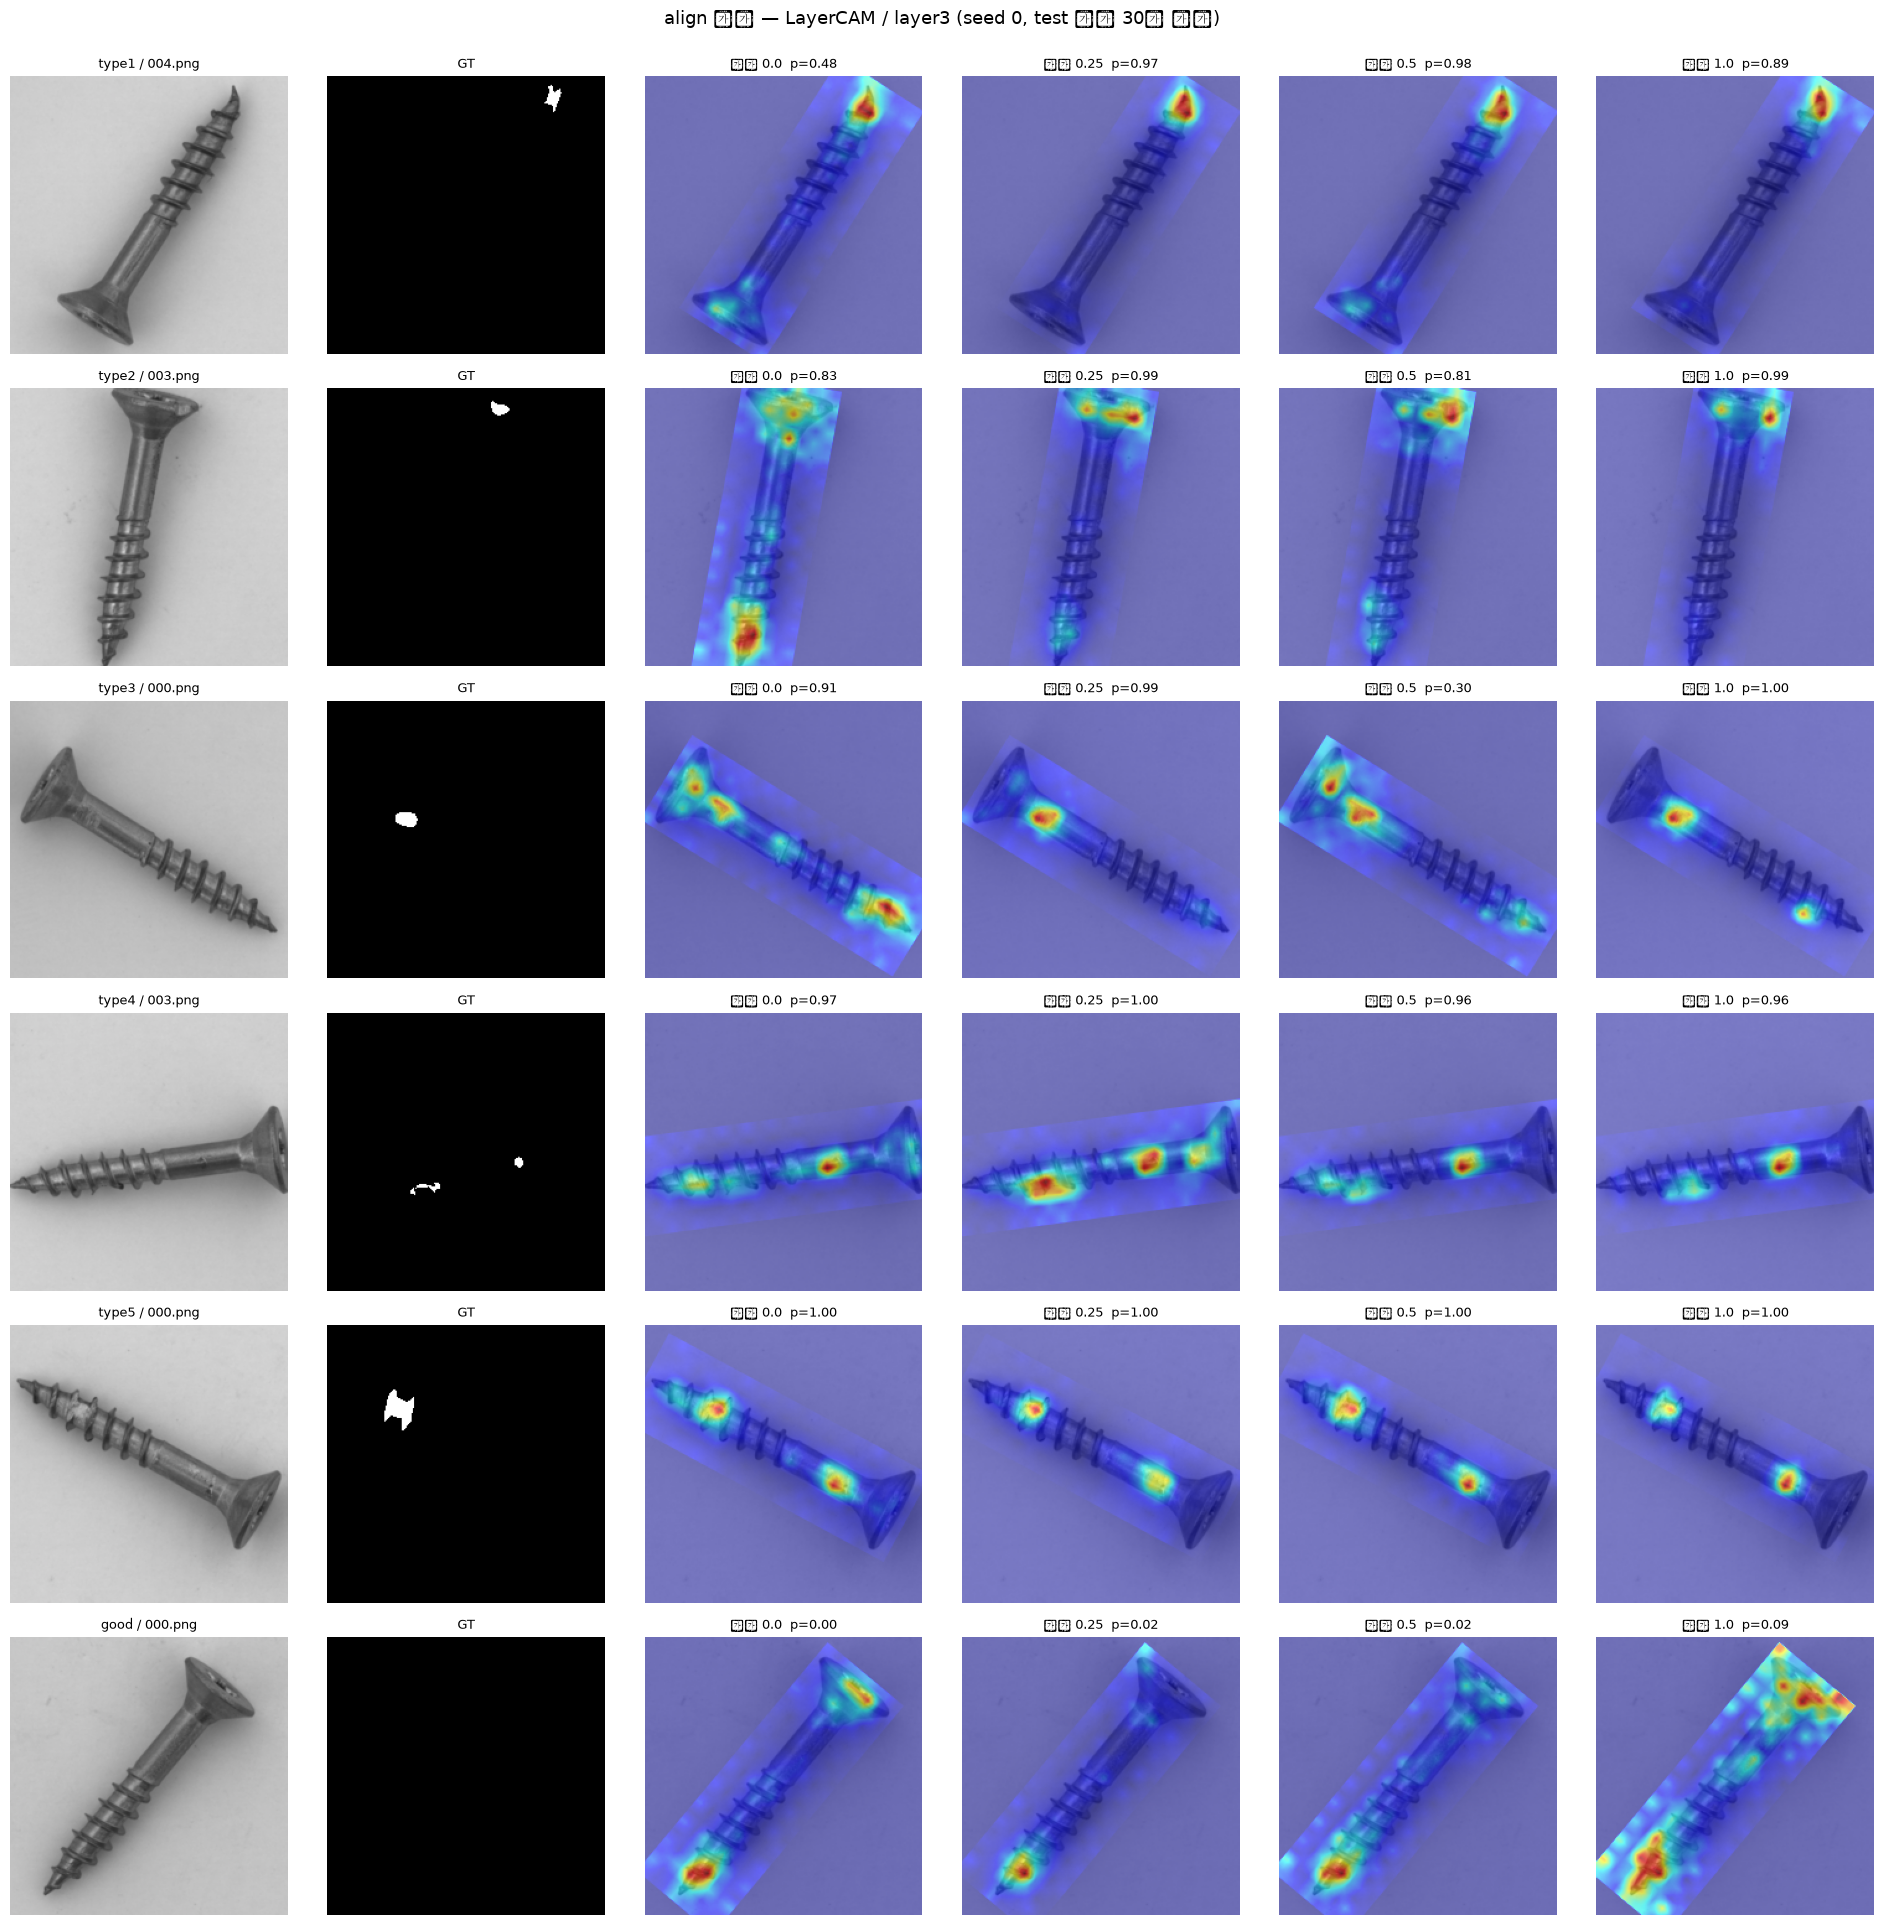

In [8]:
VIZ_SEED = 0
MODEL_DIR = os.path.join(EXP_DIR, "models"); os.makedirs(MODEL_DIR, exist_ok=True)
_mods = {}
def get_model(mode, ratio):
    k = (mode, ratio)
    if k not in _mods:
        path = os.path.join(MODEL_DIR, f"{mode}_r{ratio:.2f}_s{VIZ_SEED}.pth")
        if os.path.exists(path):
            m = build_model_bin("resnet18").to(device); m.load_state_dict(torch.load(path, map_location=device)); m.eval()
        else:
            m = train_one(mode, ratio, VIZ_SEED)[0]; torch.save(m.state_dict(), path)
            old = res[(res["mode"] == mode) & (res.ratio == ratio) & (res.seed == VIZ_SEED)]
            print(f"재학습 {mode} r={ratio}: F2 {evaluate(m, mode)['f2']:.3f} (표의 시드 0: {old.f2.iloc[0]:.3f})" if len(old) else f"학습 {mode} r={ratio}")
        _mods[k] = m
    return _mods[k]

VIZ_RECS = [next(r for r in defects if r["type"] == t) for t in synth.TYPES] + [next(r for r in test_recs if r["type"] == "good")]

def show(mode, method, layer):
    fig, axs = plt.subplots(len(VIZ_RECS), 2 + len(ratios), figsize=(3.2 * (2 + len(ratios)), 3.2 * len(VIZ_RECS)))
    maps = {r: cam_maps(get_model(mode, r), mode, method, layer, VIZ_RECS) for r in ratios}
    for i, rec in enumerate(VIZ_RECS):
        img = np.clip(inv_normalize(val_transform(Image.open(rec["path"]).convert("RGB"))).numpy().transpose(1, 2, 0), 0, 1)
        gt = load_mask(rec["mask"]) if rec["mask"] else np.zeros((224, 224), np.float32)
        axs[i, 0].imshow(img); axs[i, 0].set_title(f"{rec['type']} / {os.path.basename(rec['path'])}", fontsize=9)
        axs[i, 1].imshow(gt, cmap="gray", vmin=0, vmax=1); axs[i, 1].set_title("GT", fontsize=9)
        x = TF[mode][1](load_img(mode, rec["path"])).unsqueeze(0).to(device)
        for j, r in enumerate(ratios):
            with torch.no_grad():
                p = torch.softmax(get_model(mode, r)(x), 1)[0, 1].item()
            axs[i, 2 + j].imshow(show_cam_on_image(img, np.asarray(maps[r][i], dtype=np.float32), use_rgb=True))
            axs[i, 2 + j].set_title(f"합성 {r}  p={p:.2f}", fontsize=9)
    for a in axs.ravel(): a.axis("off")
    fig.suptitle(f"{mode} 입력 — {method} / {layer} (seed {VIZ_SEED}, test 결함 {NTEST}장 분할)", fontsize=13, y=1.0)
    plt.tight_layout(); plt.show()

for mode in MODES:
    show(mode, "GradCAM", "layer4")
    show(mode, "LayerCAM", "layer3")

## 8. 해석 시 주의
- 결함 N장·시드 5개의 표본이다. 작은 Δ 는 p 와 표준편차를 같이 본다. p 값은 다중비교 보정을 하지 않았다.
- val F2 가 포화하면 "val F2 최고 epoch" 선택이 의미 없어진다(선택 epoch 행 확인).
- 이 분할에서는 train 결함이 줄어(소스 풀 축소) baseline 분할과 조건이 다르다.